<a href="https://colab.research.google.com/github/Yu-hsiu/QuaCCAToo/blob/main/%E8%AB%96%E6%96%87%E6%A1%88%E4%BE%8B%E5%BD%99%E6%95%B4%E6%B8%AC%E8%A9%A6V1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# @title 0. 安裝 fork(Yu-hsiu/QuaCCAToo)與共用工具
# 重現簡報「2507.18759V2_程式碼驗證簡報V2」的 17 個案例(arXiv:2507.18759v2 Sec. III)。
# 程式碼取自 fork 根目錄的 verify_paper_listings.py;圖的點數見各格開頭的 N_* 參數。
import os
if not os.path.isdir('/content/QuaCCAToo'):
    !git clone -q https://github.com/Yu-hsiu/QuaCCAToo.git /content/QuaCCAToo
%cd /content/QuaCCAToo
!pip install -q -e .
!git log --oneline -1

import sys as _sys
if '/content/QuaCCAToo' not in _sys.path:
    _sys.path.insert(0, '/content/QuaCCAToo')

import copy, time, warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from qutip import basis, fidelity, fock_dm, jmat, ptrace, qeye, tensor

import quaccatoo
from quaccatoo import CPMG, NV, XY8, Hahn, PulsedSim, Rabi, compose_sys, load_quaccatoo, square_pulse

TUTORIAL_DATA = Path('/content/QuaCCAToo/docs/tutorials/sim_data_tutorials')
CACHE = Path('/content/paper_cache')
CACHE.mkdir(exist_ok=True)
NCPU = len(os.sched_getaffinity(0))
RESULTS = {}


def check(case, ok, detail):
    RESULTS[case] = bool(ok)
    print(f"[{'PASS' if ok else 'FAIL'}] {case}: {detail}")


def cached(name, sim, map_kw=None):
    """Run sim once; rerunning the cell reloads the curve from /content instead of recomputing."""
    f = CACHE / f'{name}.npy'
    if f.exists():
        return np.load(f)
    t0 = time.time()
    sim.run(map_kw=map_kw or {'num_cpus': NCPU})
    r = np.asarray(sim.results, dtype=float)
    np.save(f, r)
    print(f'{name}: {len(r)} points in {time.time() - t0:.0f} s')
    return r


print('quaccatoo', quaccatoo.__version__, '| usable cores', NCPU)


/content/QuaCCAToo
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Installing backend dependencies ... done
  Preparing editable metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 28.5/28.5 MB 48.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 97.7/97.7 kB 6.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.1/60.1 kB 4.0 MB/s eta 0:00:00
  Building editable for quaccatoo (pyproject.toml) ... done
d69b4e2 (HEAD -> main, origin/main, origin/HEAD) feat: verify every Sec. III listing of the paper and narrow the spawn warning
quaccatoo 1.3.0 | usable cores 2


w0_mw = 2799.99 MHz, w0_rf = 132.14 MHz
[PASS] A1: min 0.0000 max 1.0000
[PASS] A2: F_S(t=0.0251 us) = 0.0000


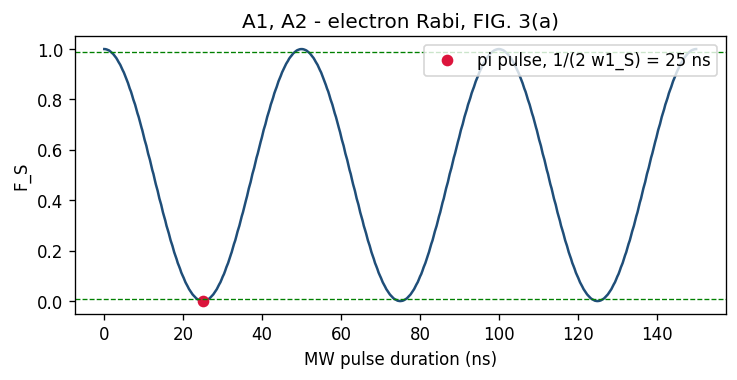

In [ ]:
# @title 案例 A1、A2｜電子 Rabi:對比 0 到 1、π 脈衝在 1/(2ω₁) = 25 ns(FIG. 3a)
sys = NV(B0=200, units_B0='mT', N=0)
GAMMA_C = 10.7084e-3
azz = 130
H2 = azz*tensor(jmat(1,'z'), jmat(1/2,'z')) \
   - GAMMA_C*sys.B0*tensor(qeye(3), jmat(1/2,'z'))
sys.add_spin(H2)
sys.rho0 = tensor(basis(3,1), basis(2,0))
w1_S, w1_I = 20, 0.8
h1 = w1_S*tensor(jmat(1,'x')*2**.5, qeye(2)) \
   + w1_I*tensor(qeye(3), jmat(1/2,'x')*2)
w0_mw = sys.energy_levels[2]
w0_rf = sys.energy_levels[1]
print(f'w0_mw = {w0_mw:.2f} MHz, w0_rf = {w0_rf:.2f} MHz')

tp_S = np.linspace(0, 0.15, 1000)
rabi_S_sim = Rabi(system=sys, pulse_duration=tp_S,
    h1=h1, pulse_params={'f_pulse': w0_mw},
    pulse_shape=square_pulse)
rabi_S_sim.run()

r = np.asarray(rabi_S_sim.results)
check('A1', r.max() > 0.99 and r.min() < 0.01, f'min {r.min():.4f} max {r.max():.4f}')
i = np.argmin(abs(tp_S - 1/(2*w1_S)))
check('A2', r[i] < 0.02, f'F_S(t={tp_S[i]:.4f} us) = {r[i]:.4f}')

fig, ax = plt.subplots(figsize=(7, 3), dpi=120)
ax.plot(tp_S*1e3, r, color='#1f4e79')
ax.plot(tp_S[i]*1e3, r[i], 'o', color='crimson', label='pi pulse, 1/(2 w1_S) = 25 ns')
for y in (0.01, 0.99):
    ax.axhline(y, ls='--', lw=0.8, color='green')
ax.set(xlabel='MW pulse duration (ns)', ylabel='F_S', title='A1, A2 - electron Rabi, FIG. 3(a)')
ax.legend(loc='upper right')
plt.show()


[PASS] A3: F_I(0) = 1.000000
[PASS] A4: t = 0.626 us, F_I = 0.109
[PASS] A5: F_I(2.5 us) = 0.687


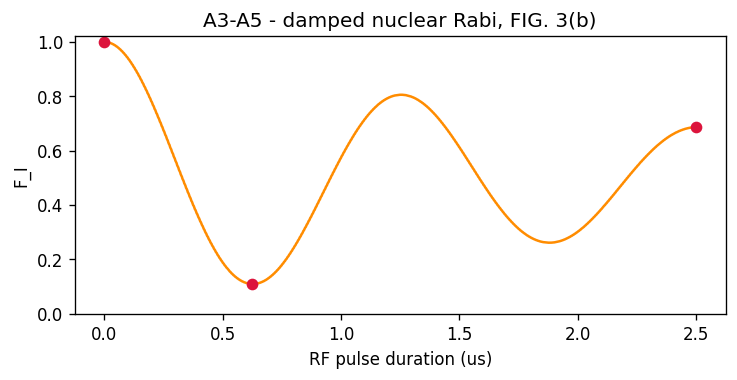

In [ ]:
# @title 案例 A3、A4、A5｜核自旋 Rabi:初態極化、極小在 0.625 µs、被退相干阻尼(FIG. 3b)
# ... system of case A1 ...
sys.rho0 = tensor(basis(3,2), basis(2,0))
sys.observable = tensor(qeye(3),
                        basis(2,0)*basis(2,0).dag())
gamma2 = .5
sys.c_ops = gamma2*tensor(qeye(3), jmat(1/2,'z'))
tp_I = np.linspace(0, 2.5, 1000)
rabi_I_sim = Rabi(system=sys, pulse_duration=tp_I,
    h1=h1, pulse_params={'f_pulse': w0_rf})
rabi_I_sim.run()
r = np.asarray(rabi_I_sim.results)

check('A3', abs(r[0] - 1) < 1e-6, f'F_I(0) = {r[0]:.6f}')
t_min = tp_I[np.argmin(r[:500])]
check('A4', abs(t_min - 0.625) < 0.1 and r.min() < 0.2, f't = {t_min:.3f} us, F_I = {r.min():.3f}')
check('A5', r[-1] > r.min() + 0.2 and r[-1] < 0.9, f'F_I(2.5 us) = {r[-1]:.3f}')

fig, ax = plt.subplots(figsize=(7, 3), dpi=120)
ax.plot(tp_I, r, color='darkorange')
ax.plot([0, t_min, tp_I[-1]], [r[0], r.min(), r[-1]], 'o', color='crimson')
ax.set(xlabel='RF pulse duration (us)', ylabel='F_I', ylim=(0, 1.02),
       title='A3-A5 - damped nuclear Rabi, FIG. 3(b)')
plt.show()


[PASS] B1: serial, max |F - authors| = 1.66e-06 over 25 tau
hahn_2000: 2000 points in 1560 s
[PASS] B2: parallel, max |F - authors| = 3.75e-06 over 2000 tau


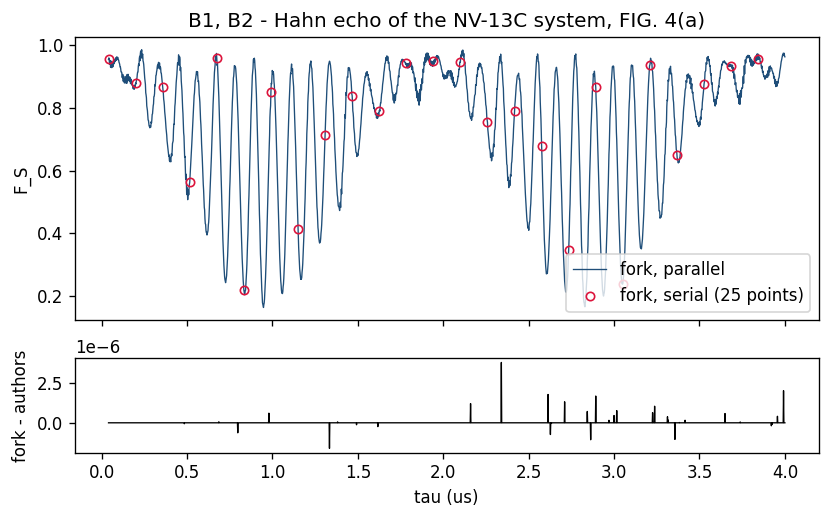

In [ ]:
# @title 案例 B1、B2｜Hahn 回波:與作者存檔逐點相同;照論文 num_cpus=32 平行執行也正確(FIG. 4a)
N_HAHN = 2000  # 論文點數;Colab 2 核心約 26 分鐘

sys1 = NV(B0=4.2, units_B0='mT', theta=-45,
          units_angles='deg', N=14,
          temp=300, units_temp='K')

# hyperfine tensor alpha and 13C Zeeman: an equation in the paper, code from tutorial 04
alpha = np.array([[5, -6.3, -2.9], [-6.3, 4.2, -2.3], [-2.9, -2.3, 8.2]])
S = [jmat(1, 'x'), jmat(1, 'y'), jmat(1, 'z')]
I = [jmat(1/2, 'x'), jmat(1/2, 'y'), jmat(1/2, 'z')]
H2 = sum(alpha[i, j]*tensor(S[i], qeye(3), I[j]) for i in range(3) for j in range(3))
H2 -= 10.705e-3*sys1.B0*tensor(qeye(3), qeye(3), np.cos(sys1.theta)*I[2] + np.sin(sys1.theta)*I[0])
sys1.add_spin(H2)

w1 = 15
w0 = np.sum(sys1.energy_levels[12:])/6 \
   - np.sum(sys1.energy_levels[1:6])/6

ref = np.load(TUTORIAL_DATA / 'Hahn_13C.npz')  # the authors' stored curve


def hahn(tau):
    return Hahn(
        free_duration=tau,
        pi_pulse_duration=0.0316,
        system=sys1, h1=w1*sys1.MW_h1,
        pulse_params={'f_pulse': w0},
        projection_pulse=True, time_steps=1000)


# B1: serial run on 25 of the 2000 tau values
idx = np.arange(0, 2000, 80)
hahn_sim = hahn(ref['tau'][idx])
hahn_sim.run()          # serial
dev = np.max(np.abs(np.asarray(hahn_sim.results) - ref['results'][idx]))
check('B1', dev < 1e-3, f"serial, max |F - authors| = {dev:.2e} over {len(idx)} tau")

# B2: the listing itself, run(map_kw={'num_cpus': 32}); the fork caps 32 to the usable cores
tau_hahn = np.linspace(0.04, 4, N_HAHN)
with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    F_hahn = cached(f'hahn_{N_HAHN}', hahn(tau_hahn), map_kw={'num_cpus': 32})
if N_HAHN == 2000:
    diff = F_hahn - ref['results']
else:
    diff = F_hahn - np.interp(tau_hahn, ref['tau'], ref['results'])
check('B2', np.max(np.abs(diff)) < 1e-3, f"parallel, max |F - authors| = {np.max(np.abs(diff)):.2e} over {N_HAHN} tau")

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(8, 4.5), dpi=120, sharex=True, height_ratios=[3, 1])
ax.plot(tau_hahn, F_hahn, lw=0.8, color='#1f4e79', label='fork, parallel')
ax.plot(ref['tau'][idx], np.asarray(hahn_sim.results), 'o', mfc='none', color='crimson', ms=5, label='fork, serial (25 points)')
ax.set(ylabel='F_S', title='B1, B2 - Hahn echo of the NV-13C system, FIG. 4(a)')
ax.legend(loc='lower right')
ax2.plot(tau_hahn, diff, lw=0.8, color='k')
ax2.set(xlabel='tau (us)', ylabel='fork - authors')
plt.show()


/content/QuaCCAToo/quaccatoo/pulsed_sim/predef_dd_seqs.py:105: UserWarning: {'atol': 1e-16, 'rtol': 1e-16} is below the double precision floor of 1e-14 that the integrator can hold over a long sequence. The extra steps multiply the runtime without changing the result.
  self._check_attr_predef_seqs(


cpmg16_as_printed: 6 points in 278 s
[PASS] B3: M=16, max |F - authors| = 9.71e-05 over 6 tau
cpmg_bright_M16_100: 100 points in 696 s
M = 16: -y dip 0.781 at 16.7756 us | 1 - authors 0.784
cpmg_bright_M32_100: 100 points in 1389 s
M = 32: -y dip 0.340 at 16.7911 us | 1 - authors 0.348
cpmg_bright_M56_100: 100 points in 2416 s
M = 56: -y dip 0.038 at 16.7967 us | 1 - authors 0.041
cpmg_bright_M96_100: 100 points in 4068 s
M = 96: -y dip 0.570 at 16.7733 us | 1 - authors 0.649


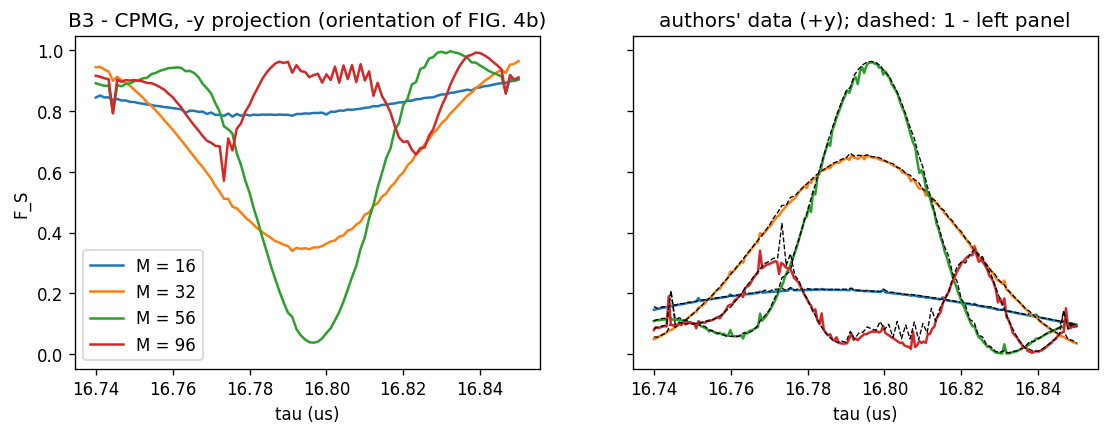

In [ ]:
# @title 案例 B3｜CPMG:與作者存檔相符;改用 −y 投影脈衝得到論文方向的圖(FIG. 4b)
N_CPMG = 100  # 每條曲線點數;論文 200(Colab 4 條共約 70 分鐘)

# sys2 and H2: prose and an equation in the paper, code from tutorial 04
sys2 = NV(B0=40.1, units_B0='mT', N=14)
tpi = 0.01
w1 = 1/tpi/2
axz = 0.055*np.sin(np.pi*54/180)
azz = 0.055*np.cos(np.pi*54/180)
H2 = (axz*(tensor(jmat(1, 'x'), qeye(3), jmat(1/2, 'z')) + tensor(jmat(1, 'z'), qeye(3), jmat(1/2, 'x')))
      + azz*tensor(jmat(1, 'z'), qeye(3), jmat(1/2, 'z'))
      - 10.705e-3*sys2.B0*tensor(qeye(3), qeye(3), jmat(1/2, 'z')))
sys2.add_spin(H2)
w0 = np.mean(sys2.energy_levels[6:12]) - np.sum(sys2.energy_levels[1:6])/6

# check: the listing as printed, M=16, 6 of the 200 tau values across the resonance
ref16 = load_quaccatoo(str(TUTORIAL_DATA / 'CPMG-16_13C'))
idx = np.array([0, 60, 90, 100, 110, 199])
M = 16
sol_opt = {'atol':1e-16, 'rtol':1e-16,
           'nsteps':1e8, 'order':30}
tau_cpmg = np.asarray(ref16.variable)[idx]
cpmg_sim = CPMG(free_duration=tau_cpmg,
    pi_pulse_duration=0.01, system=sys2,
    h1=w1*sys2.MW_h1,
    pulse_params={'f_pulse': w0},
    M=M, time_steps=1000, options=sol_opt)
F16 = cached('cpmg16_as_printed', cpmg_sim)
dev = np.max(np.abs(F16 - np.asarray(ref16.results)[idx]))
# the paper prints 0.01, the authors' data used 0.00999483, hence the looser bound
check('B3', dev < 5e-3, f"M=16, max |F - authors| = {dev:.2e} over {len(idx)} tau")


# figure: same sequence, projection pulse on -y, so the background ends bright as in FIG. 4(b)
class CPMGBright(CPMG):
    def CPMG_sequence(self, tau):
        minus_y = {**self.pulse_params[1],
                   'phi_t': np.pi/2}   # was -pi/2
        ps = tau - self.pi_pulse_duration
        self._reset_sequence()
        self._pulse(self.Ht, self.pi_pulse_duration/2, self.options, self.pulse_params[1])
        self._free_evolution(ps/2 - self.pi_pulse_duration/2, self.options)
        for idx_M in range(self.M):
            self._pulse(self.Ht, self.pi_pulse_duration, self.options, self.pulse_params[0])
            if idx_M != self.M - 1:
                self._free_evolution(ps, self.options)
        self._free_evolution(ps/2 - self.pi_pulse_duration/2, self.options)
        self._pulse(self.Ht, self.pi_pulse_duration/2, self.options, minus_y)
        return self.rho


# 1e-16 is below double precision and only costs time; these tolerances change F by 1e-7 to 1e-5
fig_opt = {'atol': 1e-12, 'rtol': 1e-10, 'nsteps': 1e8, 'order': 30}
tau_fig = np.linspace(16.74, 16.85, N_CPMG)
fig, (ax, ax2) = plt.subplots(1, 2, figsize=(11, 3.6), dpi=120, sharey=True)
for M in (16, 32, 56, 96):
    bright = cached(f'cpmg_bright_M{M}_{N_CPMG}', CPMGBright(free_duration=tau_fig,
        pi_pulse_duration=0.01, system=sys2, h1=w1*sys2.MW_h1,
        pulse_params={'f_pulse': w0}, M=M, time_steps=1000, options=fig_opt))
    ref = load_quaccatoo(str(TUTORIAL_DATA / f'CPMG-{M}_13C'))
    stored = np.asarray(ref.results, dtype=float)
    line, = ax.plot(tau_fig, bright, label=f'M = {M}')
    ax2.plot(np.asarray(ref.variable), stored, color=line.get_color(), label=f'authors, M = {M}')
    ax2.plot(tau_fig, 1 - bright, '--', color='k', lw=0.8)
    print(f'M = {M}: -y dip {bright.min():.3f} at {tau_fig[bright.argmin()]:.4f} us | 1 - authors {1 - stored.max():.3f}')
ax.set(xlabel='tau (us)', ylabel='F_S', title='B3 - CPMG, -y projection (orientation of FIG. 4b)')
ax2.set(xlabel='tau (us)', title="authors' data (+y); dashed: 1 - left panel")
ax.legend()
plt.show()


In [ ]:
# @title 案例 B4｜XY8-12:交流場在 τ0 = 1/(2·5.5 MHz) ≈ 0.091 µs 共振(FIG. 5b)
# tutorial 05 的 100 點 τ 網格。實驗室座標系裡 1.7 GHz 載波讓訊號在 τ 差不到 1 ns 時就跳動,
# 所以檢查點必須落在這組網格上;論文作圖用 1000 點(Colab 上每條曲線要數小時)。
tau_xy8 = np.linspace(0.06, 0.17, 100)
base, peak, harm = [0, 5, 10], [28, 29], [47, 48, 49, 68, 69, 70]


def B2(t, gamma_B2=0.3, w2=5.5):   # as the text says
    return gamma_B2*np.sin(w2*t)


qsys3 = NV(N=15, B0=40, units_B0='mT')
H2 = [tensor(jmat(1,'z'), qeye(2)), B2]
w1 = 20
xy8_sim = XY8(M=12, free_duration=tau_xy8,
    pi_pulse_duration=1/2/w1, system=qsys3,
    h1=w1*qsys3.MW_h1,
    pulse_params={'f_pulse': qsys3.MW_freqs[0]},
    H2=H2)
F_xy8 = cached('xy8_100', xy8_sim)

check('B4', F_xy8[peak].min() > 0.9 and F_xy8[base].max() < 0.1,
      f'F_S = {np.round(F_xy8[peak], 3).tolist()} at tau = {np.round(tau_xy8[peak], 4).tolist()} us, baseline <= {F_xy8[base].max():.3f}')

tau0 = 1/(2*5.5)
fig, ax = plt.subplots(figsize=(8, 3.2), dpi=120)
ax.plot(tau_xy8, F_xy8, color='#1f4e79')
ax.axvline(tau0, ls='--', lw=0.8, color='gray')
ax.set(xlabel='tau (us)', ylabel='F_S', ylim=(0, 1.02), title='B4 - XY8-12 sensing a 5.5 MHz field, FIG. 5(b)')
plt.show()


xy8_100: 100 points in 2989 s
[PASS] B4: F_S = [0.974, 0.976] at tau = [0.0911, 0.0922] us, baseline <= 0.030


In [ ]:
# @title 案例 B5｜照論文印的 B2(t) 預設值跑,共振消失(論文印刷錯誤)
# B5、B6 只算 verify_paper_listings.py 的 11 個檢查點(基線 3、共振 2、假諧波 6),都在 B4 的 100 點網格上。
# Colab 免費執行階段在 50 分鐘的長運算後會被回收,所以這兩格自帶定義、不依賴 B4 的變數。
grid = np.linspace(0.06, 0.17, 100)
base, peak, harm = [0, 5, 10], [28, 29], [47, 48, 49, 68, 69, 70]
tau_chk = grid[base + peak + harm]
b, p, h = slice(0, 3), slice(3, 5), slice(5, 11)
tau0 = 1/(2*5.5)
qsys3 = NV(N=15, B0=40, units_B0='mT')
w1 = 20


def B2(t, gamma_B2=0.3, w2=5.5):   # as the text says
    return gamma_B2*np.sin(w2*t)


# B2(t) field definition, AS PRINTED in the paper
def B2_printed(t, gamma_B2=5.5, w2=0.3):
    return gamma_B2*np.sin(w2*t)


def xy8(field, **kw):
    H2 = [tensor(jmat(1,'z'), qeye(2)), field]
    return XY8(M=12, free_duration=tau_chk,
        pi_pulse_duration=1/2/w1, system=qsys3,
        h1=w1*qsys3.MW_h1,
        pulse_params={'f_pulse': qsys3.MW_freqs[0]},
        H2=H2, **kw)


F_text = cached('xy8_chk', xy8(B2))
F_printed = cached('xy8_printed_chk', xy8(B2_printed))

# text: gamma_e*B2 = 0.3 MHz, w2 = 5.5 MHz
check('B5', F_printed[p].max() < 0.9,
      f'F_S at tau0 = {np.round(F_printed[p], 3).tolist()} (as the text says: {np.round(F_text[p], 3).tolist()}); '
      f'harmonic points {np.round(F_printed[h], 3).tolist()}: FIG. 5 is not reproduced')

fig, ax = plt.subplots(figsize=(8, 3.2), dpi=120)
ax.plot(tau_chk, F_text, 'o-', color='lightsteelblue', label='as the text says')
ax.plot(tau_chk, F_printed, 'o-', color='crimson', label='defaults as printed')
ax.axvline(tau0, ls='--', lw=0.8, color='gray')
ax.set(xlabel='tau (us)', ylabel='F_S', ylim=(0, 1.02), title='B5 - XY8-12 with the printed B2 defaults (11 check points)')
ax.legend()
plt.show()


In [ ]:
# @title 案例 B6｜RXY8-12:主共振保留、假諧波被壓掉(FIG. 5c)
F_rxy8 = cached('rxy8_chk', xy8(B2, RXY8=True,
    seed=1))   # seed is not in the paper; reproducible

# harmonics near 5/4, 3/2 of tau0
check('B6', F_rxy8[p].min() > 0.9 and F_rxy8[h].max() < F_text[h].max(),
      f'peak F_S = {np.round(F_rxy8[p], 3).tolist()}; harmonics max XY8 {F_text[h].max():.3f} vs RXY8 {F_rxy8[h].max():.3f}')

fig, ax = plt.subplots(figsize=(8, 3.2), dpi=120)
ax.plot(tau_chk, F_text, 'o-', color='lightsteelblue', label='XY8-12')
ax.plot(tau_chk, F_rxy8, 'o-', color='crimson', label='RXY8-12')
for k in (3/4, 1, 5/4, 3/2, 7/4):
    if tau_chk[0] < k*tau0 < tau_chk[-1]:
        ax.axvline(k*tau0, ls='--', lw=0.8, color='gray')
ax.set(xlabel='tau (us)', ylabel='F_S', ylim=(0, 1.02), title='B6 - RXY8-12 suppresses the spurious harmonics (11 check points)')
ax.legend()
plt.show()


In [ ]:
# @title III C 共用程式｜隱形傳態序列(CNOT、重聚焦、Hadamard)與 Bob 的重建旋轉
def teleport_until_measurement(alpha, beta, phi_rf):
    """Sec. III C listings up to Alice's measurement."""
    # System definition
    NVb = NV(B0=18, units_B0='mT', N=0)
    NVa = NV(B0=25, units_B0='mT', N=14)
    NVb.truncate(mS=1)
    NVa.truncate(mS=1, mI=1)
    sys = compose_sys(NVb, NVa)

    # Initial state definition
    Psi_ = tensor(basis(2,0),basis(2,1)) \
         - tensor(basis(2,1),basis(2,0))
    psi = alpha*basis(2,0) + beta*basis(2,1)
    sys.rho0 = tensor(Psi_, psi).unit()

    # Sequence instantiation
    seq = PulsedSim(sys)

    # CNOT gate
    sol_opt = {'nsteps': 1e9}
    w0_cnot = NVa.energy_levels[2]
    w1_cnot = 2.14/3**0.5
    tpi_cnot = 1/(2*w1_cnot)
    h1_cnot = w1_cnot*tensor(qeye(2), NVa.MW_h1)
    seq.add_pulse(duration=tpi_cnot, h1=h1_cnot,
                  pulse_params={'f_pulse': w0_cnot, 'phi_t': np.pi/2}, options=sol_opt)

    # Hadamard gate parameters (printed after the refocus, needed here for tau1 and tau2)
    w0_rf = NVa.RF_freqs[2]
    w0_mwa = NVa.MW_freqs[0]
    w1_rf = 0.2
    w1_mwa = 16
    tpi_rf = 1/(2*w1_rf)
    tpi_mwa = 1/(2*w1_mwa)
    h1_rf = w1_rf*tensor(qeye(2), NVa.RF_h1)
    h1_mwa = w1_mwa*tensor(qeye(2), NVa.MW_h1)

    # Refocus; tau1 and tau2 from the equation in the text and the 2.26 us total (tutorial 06)
    w1_mwb = 22
    tpi_mwb = 1/(2*w1_mwb)
    w0_mwb = NVb.MW_freqs[0]
    h1_mwb = w1_mwb*tensor(NVb.MW_h1, qeye(2), qeye(2))
    tau_refocus = 2.26
    T = tpi_cnot + tau_refocus + tpi_rf/2 + tpi_mwa + tpi_rf/2
    tau1 = T/2 - tpi_cnot - tpi_mwb/2
    tau2 = tau_refocus - tau1 - tpi_mwb
    seq.add_free_evolution(tau1)
    seq.add_pulse(duration=tpi_mwb, h1=h1_mwb,
                  pulse_params={'f_pulse': w0_mwb, 'phi_t': np.pi/2}, options=sol_opt)
    seq.add_free_evolution(tau2)

    # Hadamard gate
    seq.add_pulse(duration=tpi_rf/2, h1=h1_rf,
                  pulse_params={'f_pulse': w0_rf, 'phi_t': phi_rf}, options=sol_opt)
    seq.add_pulse(duration=tpi_mwa, h1=h1_mwa,
                  pulse_params={'f_pulse': w0_mwa, 'phi_t': np.pi/2}, options=sol_opt)
    seq.add_pulse(duration=tpi_rf/2, h1=h1_rf,
                  pulse_params={'f_pulse': w0_rf, 'phi_t': phi_rf}, options=sol_opt)

    bob = {'tpi': tpi_mwb, 'h1': h1_mwb, 'w0': w0_mwb, 'sol_opt': sol_opt}
    return seq, psi, bob


def bob_reconstruct(seq, label, c0, c1, bob):
    """U(c0, c1) of Table I, with the pulses and tau3 of tutorial 06."""
    tpi, h1, w0, opt = bob['tpi'], bob['h1'], bob['w0'], bob['sol_opt']
    if label == '+Z':
        # State reconstruction, as printed
        if c0 == 0:
            seq.add_pulse(tpi, h1, pulse_params={'f_pulse': w0, 'phi_t': np.pi/2}, options=opt)
        return
    tau3 = np.ceil(w0*tpi/2)/w0 - tpi/2
    rz = 1/(2*w0)  # R_z(pi) as a free evolution
    # phi_t of the pi/2 pulse and the extra R_z(pi), per outcome
    table = {
        '+X': {(0, 0): (-np.pi/2, 0), (0, 1): (np.pi/2, rz), (1, 0): (np.pi/2, rz), (1, 1): (-np.pi/2, 0)},
        '+Y': {(0, 0): (0, rz), (0, 1): (np.pi, 0), (1, 0): (0, rz), (1, 1): (np.pi, 0)},
    }
    phi, extra = table[label][(c0, c1)]
    seq.add_pulse(tpi/2, h1, pulse_params={'f_pulse': w0, 'phi_t': phi}, options=opt)
    seq.add_free_evolution(tau3 + extra)


PHI_RF = 2.95  # paper: calibrated to 2.95 rad (169 deg)
TABLE_I = {'+X': [0.9624, 0.9814, 0.9889, 0.9878],
           '+Y': [0.9585, 0.9713, 0.9779, 0.9945],
           '+Z': [0.9999, 0.9998, 0.9985, 0.9981]}
OUTCOMES = [(0, 0), (0, 1), (1, 0), (1, 1)]


def teleport_case(label, alpha, beta, case_measure, case_fidelity):
    seq, psi, bob = teleport_until_measurement(alpha, beta, PHI_RF)

    # Alice measurements, as printed (the outcome is random)
    listing = copy.deepcopy(seq)
    obs0 = tensor(qeye(2), fock_dm(2,0), qeye(2))
    c0 = 1 - listing.measure_qsys(observable=obs0)
    obs1 = tensor(qeye(2), qeye(2), fock_dm(2,1))
    c1 = listing.measure_qsys(observable=obs1)
    check(case_measure, {c0, c1} <= {0., 1.}, f'input {label}: c0 = {c0}, c1 = {c1}')

    # every outcome of Table I, by projecting instead of sampling
    probs, fids, rhos = [], [], []
    for c0, c1 in OUTCOMES:
        branch = copy.deepcopy(seq)
        P = tensor(qeye(2), fock_dm(2,c0), fock_dm(2,c1))
        # the long pulse sequence leaves the ket slightly shorter than 1, so normalise first
        probs.append(((P*branch.rho).norm()/branch.rho.norm())**2)
        branch.rho = (P*branch.rho).unit()
        bob_reconstruct(branch, label, c0, c1, bob)
        rho_bob = ptrace(branch.rho*branch.rho.dag(), 0)
        rhos.append(rho_bob)
        # Table I quotes QuTiP's fidelity, sqrt(<psi|rho|psi>) for a pure target
        fids.append(fidelity(rho_bob, psi*psi.dag()))
    dev = np.max(np.abs(np.array(fids) - TABLE_I[label]))
    check(case_fidelity, dev < 1e-3, f'input {label}: fork {np.round(fids, 4).tolist()} | paper {TABLE_I[label]}')

    names = ['00', '01', '10', '11']
    x = np.arange(4)
    fig, axs = plt.subplots(1, 4, figsize=(15, 3), dpi=110)
    axs[0].bar(names, probs, color='#1f4e79')
    axs[0].axhline(0.25, ls='--', lw=0.8, color='gray')
    axs[0].set(xlabel='c0 c1', ylim=(0, 0.4), title=f'{case_measure} - outcome probabilities, input {label}')
    ideal = (psi*psi.dag()).full().ravel()
    sim = rhos[3].full().ravel()  # outcome 11, as FIG. 7 shows one outcome
    for ax, part, name in ((axs[1], np.real, 'Re'), (axs[2], np.imag, 'Im')):
        ax.bar(x - 0.2, part(ideal), 0.4, color='lightgray', label='ideal')
        ax.bar(x + 0.2, part(sim), 0.4, color='#1f4e79', label='fork')
        ax.set(xticks=x, xticklabels=['00', '01', '10', '11'], ylim=(-0.6, 1.05), title=f'{name} rho_Bob, outcome 11 (FIG. 7)')
    axs[1].legend()
    axs[3].bar(x - 0.2, TABLE_I[label], 0.4, color='lightgray', label='paper Table I')
    axs[3].bar(x + 0.2, fids, 0.4, color='crimson', label='fork')
    axs[3].set(xticks=x, xticklabels=names, xlabel='c0 c1', ylim=(0.9, 1.005), title=f'{case_fidelity} - fidelity vs Table I')
    axs[3].legend(loc='lower right')
    plt.show()


[PASS] C1: input +X: c0 = 1.0, c1 = 0.0
[PASS] C2: input +X: fork [0.9623, 0.9814, 0.989, 0.9878] | paper [0.9624, 0.9814, 0.9889, 0.9878]


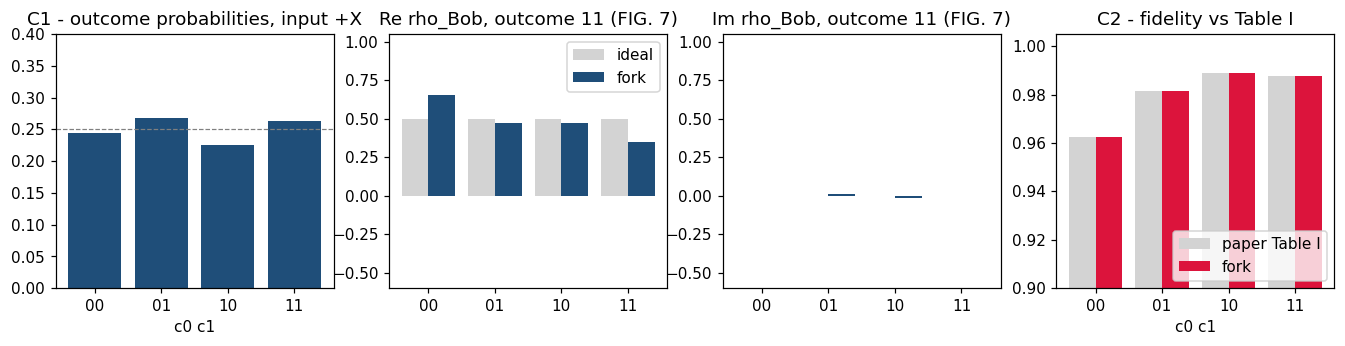

In [ ]:
# @title 案例 C1、C2｜輸入 |+X⟩:Alice 的量測與 Bob 重建後的保真度(FIG. 7、Table I)
alpha, beta = 1/2**.5, 1/2**.5
teleport_case('+X', alpha, beta, 'C1', 'C2')


[PASS] C3: input +Y: c0 = 1.0, c1 = 1.0
[PASS] C4: input +Y: fork [0.9585, 0.9713, 0.9779, 0.9945] | paper [0.9585, 0.9713, 0.9779, 0.9945]


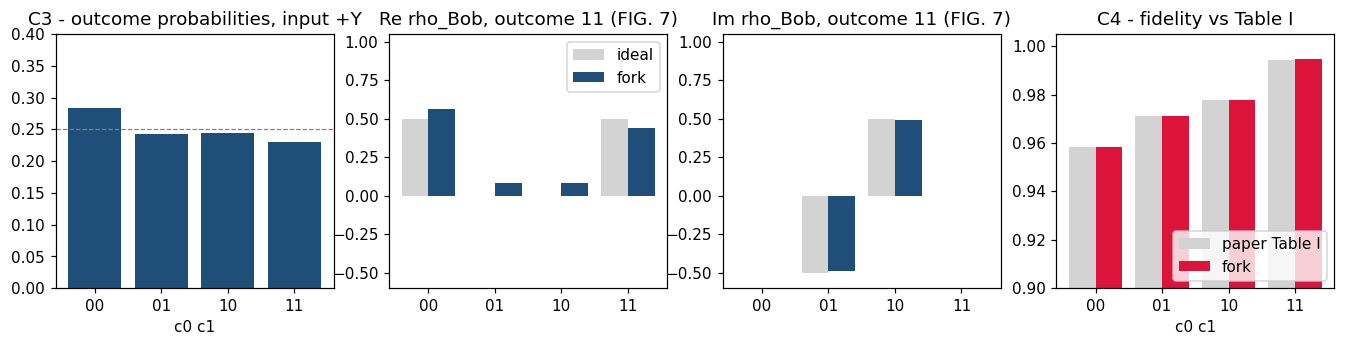

In [ ]:
# @title 案例 C3、C4｜輸入 |+Y⟩:Alice 的量測與 Bob 重建後的保真度(FIG. 7、Table I)
alpha, beta = 1/2**.5, 1j/2**.5
teleport_case('+Y', alpha, beta, 'C3', 'C4')


[PASS] C5: input +Z: c0 = 1.0, c1 = 0.0
[PASS] C6: input +Z: fork [0.9999, 0.9998, 0.9985, 0.9981] | paper [0.9999, 0.9998, 0.9985, 0.9981]


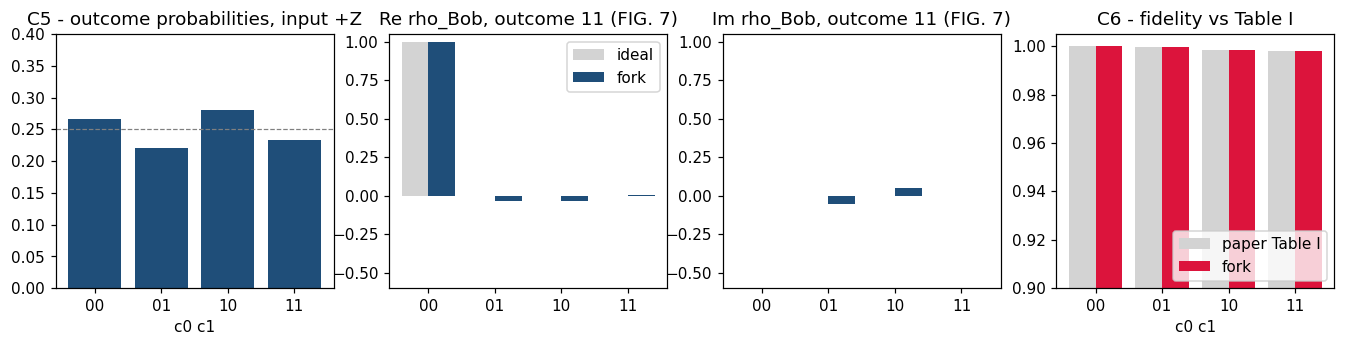

In [ ]:
# @title 案例 C5、C6｜輸入 |+Z⟩:Alice 的量測與 Bob 重建後的保真度(FIG. 7、Table I)
alpha, beta = 1, 0
teleport_case('+Z', alpha, beta, 'C5', 'C6')


In [ ]:
# @title 總結｜本次執行階段跑過的案例
# B1-B4 要跑 26 分鐘到 2 小時以上,Colab 會在長運算後回收執行階段,
# 所以它們可能是在較早的執行階段跑完的:結果看各格自己的 [PASS] 輸出。
CASES = ['A1', 'A2', 'A3', 'A4', 'A5', 'B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'C1', 'C2', 'C3', 'C4', 'C5', 'C6']
for case in CASES:
    print(case, {True: 'PASS', False: 'FAIL', None: 'not run in this session'}[RESULTS.get(case)])
assert all(RESULTS.values()), 'a check failed'
print(f'\n{sum(RESULTS.values())}/{len(RESULTS)} of the checks run in this session passed')


 07:44:45 up  3:38,  0 user,  load average: 0.49, 0.49, 0.78
ls: cannot access '/content/paper_cache': No such file or directory
/content:
total 16
drwxr-xr-x 1 root root 4096 Oct  2 13:50 .
drwxr-xr-x 1 root root 4096 Oct  6 07:11 ..
drwxr-xr-x 4 root root 4096 Oct  2 13:50 .config
drwxr-xr-x 1 root root 4096 Oct  2 13:50 sample_data
